<a href="https://colab.research.google.com/github/ranispl/FSOI/blob/develop/orbit_1month.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import xarray as xr
import matplotlib.pyplot as plt
import os

file_path = '/content/orbit_2026_10_01.nc'

if os.path.exists(file_path):
    try:
        # Open the dataset
        ds = xr.open_dataset(file_path)
        print("Dataset structure:")
        print(ds)

        # Attempt to find latitude and longitude variables
        lat_name = None
        lon_name = None
        for col in ds.variables:
            if 'lat' in col.lower():
                lat_name = col
            elif 'lon' in col.lower():
                lon_name = col

        if lat_name and lon_name:
            lats = ds[lat_name].values
            lons = ds[lon_name].values

            # Plotting the orbital path
            plt.figure(figsize=(10, 6))
            plt.scatter(lons, lats, c=range(len(lats)), cmap='viridis', s=10, label='Orbital Path')
            plt.colorbar(label='Time step / Index')
            plt.title(f'Orbital Pass Plot ({os.path.basename(file_path)})')
            plt.xlabel('Longitude')
            plt.ylabel('Latitude')
            plt.grid(True, linestyle='--', alpha=0.5)
            plt.xlim(-180, 180)
            plt.ylim(-90, 90)
            plt.show()
        else:
            print("Could not automatically detect latitude and longitude columns in the NetCDF file.")
    except OSError as e:
        print(f"An error occurred while trying to open the file: {e}")
        print("\nThis error typically means the file is truncated, damaged, or incomplete.")
        print("Please verify the file size and try re-uploading the complete file to the environment.")
else:
    print(f"File not found at {file_path}")

An error occurred while trying to open the file: Unable to synchronously open file (truncated file: eof = 24117248, sblock->base_addr = 0, stored_eof = 87341918)

This error typically means the file is truncated, damaged, or incomplete.
Please verify the file size and try re-uploading the complete file to the environment.


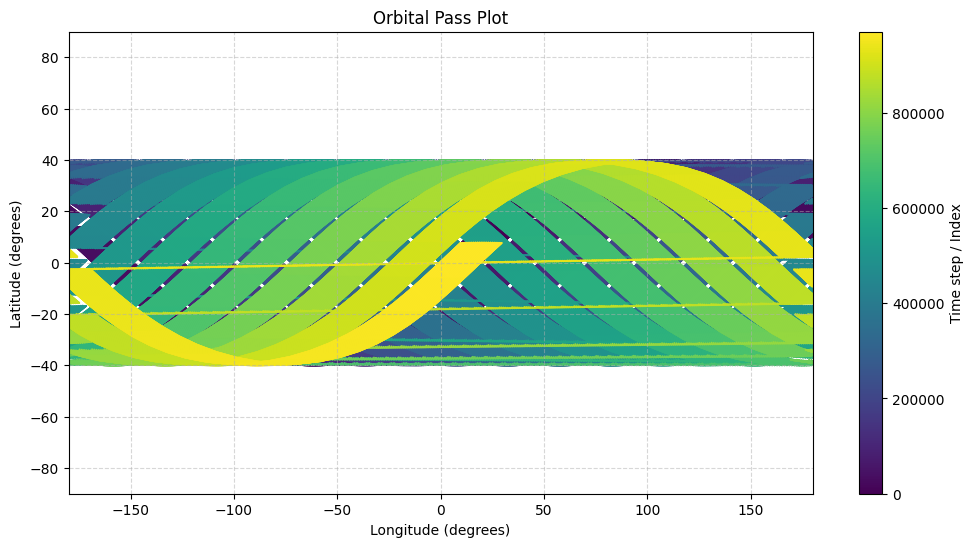

In [9]:
import matplotlib.pyplot as plt
from netCDF4 import Dataset

file_path = "/content/orbit_2026_10_01.nc"

try:
    with Dataset(file_path, "r") as nc_file:
        # Read latitude and longitude
        lat = nc_file.variables["latitude_deg"][:]
        lon = nc_file.variables["longitude_deg"][:]

        # Create the plot
        plt.figure(figsize=(12, 6))

        # Plot orbital pass
        scatter = plt.scatter(lon, lat, c=range(len(lat)), cmap="viridis", s=2, edgecolor="none")

        plt.colorbar(scatter, label="Time step / Index")
        plt.xlabel("Longitude (degrees)")
        plt.ylabel("Latitude (degrees)")
        plt.title("Orbital Pass Plot")
        plt.grid(True, linestyle="--", alpha=0.5)
        plt.xlim(-180, 180)
        plt.ylim(-90, 90)
        plt.show()
except Exception as e:
    print(f"Error plotting the orbital pass: {e}")

In [10]:
!pip install cartopy netCDF4 matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 20.9 MB/s  0:00:00


Available variables: ['latitude_deg', 'longitude_deg', 'track_distance_km', 'cross_track_offset_km', 'swath_width_km', 'swath_edge_flag', 'sun_elevation_deg', 'sun_zenith_deg', 'sun_azimuth_deg', 'satellite_azimuth_deg', 'satellite_elevation_deg', 'local_solar_time_h', 'sunlit']


/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


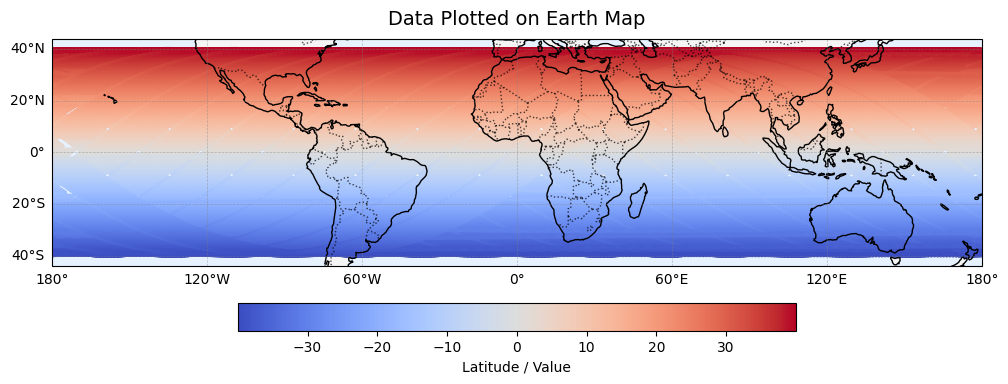

In [12]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
from netCDF4 import Dataset

# Replace with the path to your HDF/NetCDF file
file_path = "/content/orbit_2026_10_01.nc"

try:
  with Dataset(file_path, "r") as nc_file:
    # Print available variables to check exact names if needed
    print("Available variables:", list(nc_file.variables.keys()))

    # Extract latitude and longitude variables
    # (Adjust variable names 'latitude_deg' or 'longitude_deg' based on your file)
    lat = nc_file.variables["latitude_deg"][:]
    lon = nc_file.variables["longitude_deg"][:]

    # Create the figure with a geographic projection
    fig = plt.figure(figsize=(12, 6))
    ax = plt.axes(projection=ccrs.PlateCarree())

    # Add background map features
    ax.add_feature(cfeature.COASTLINE)
    ax.add_feature(cfeature.BORDERS, linestyle=":", alpha=0.7)
    ax.add_feature(cfeature.LAND, color="#f5f5f5")
    ax.add_feature(cfeature.OCEAN, color="#e6f2ff")

    # Plot data points using PlateCarree transformation
    # (Use plt.contourf(lon, lat, data, transform=ccrs.PlateCarree()) if your data is gridded)
    scatter = ax.scatter(
        lon,
        lat,
        c=lat,  # Replace with your actual data variable if desired
        cmap="coolwarm",
        s=8,
        transform=ccrs.PlateCarree(),
        edgecolor="none",
    )

    # Add gridlines with latitude and longitude labels
    gl = ax.gridlines(
        draw_labels=True, linewidth=0.5, color="gray", alpha=0.5, linestyle="--"
    )
    gl.top_labels = False
    gl.right_labels = False

    # Add a colorbar
    plt.colorbar(
        scatter,
        ax=ax,
        orientation="horizontal",
        pad=0.08,
        shrink=0.6,
        label="Latitude / Value",
    )

    plt.title("Data Plotted on Earth Map", fontsize=14, pad=10)
    plt.show()

except Exception as e:
  print(f"Error reading the file: {e}")

In [15]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
from netCDF4 import Dataset
import numpy as np

# Replace with your actual file path
file_path = "/content/orbit_2026_10_01.nc"

try:
  with Dataset(file_path, "r") as nc_file:
    # Extract latitude and longitude along the orbit
    # (Adjust variable names if your file uses 'lat' / 'lon')
    lat = nc_file.variables["latitude"][:]
    lon = nc_file.variables["longitude"][:]

    # Handle International Date Line crossings to prevent weird streaks
    # If longitude changes by more than 180 degrees between steps, break the line
    lon_diff = np.abs(np.diff(lon))
    break_indices = np.where(lon_diff > 180)[0]

    lon_plot = lon.copy().astype(float)
    lat_plot = lat.copy().astype(float)
    if len(break_indices) > 0:
      lon_plot = np.insert(lon_plot, break_indices + 1, np.nan)
      lat_plot = np.insert(lat_plot, break_indices + 1, np.nan)

    # Set up the map projection
    fig = plt.figure(figsize=(12, 6))
    ax = plt.axes(projection=ccrs.PlateCarree())

    # Add background map features
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linestyle=":", alpha=0.5)
    ax.add_feature(cfeature.LAND, color="#f0f0f0")
    ax.add_feature(cfeature.OCEAN, color="#e4f1fe")

    # Plot the orbital path line
    ax.plot(
        lon_plot,
        lat_plot,
        color="crimson",
        linewidth=1.5,
        transform=ccrs.PlateCarree(),
        label="Orbital Track",
    )

    # Add gridlines and labels
    gl = ax.gridlines(
        draw_labels=True, linewidth=0.5, color="gray", alpha=0.5, linestyle="--"
    )
    gl.top_labels = False
    gl.right_labels = False

    ax.legend(loc="upper right")
    plt.title("Satellite Orbital Path", fontsize=14, pad=10)
    plt.show()

except Exception as e:
  print(f"Error processing orbital data: {e}")

Error processing orbital data: 'latitude'


In [16]:
from netCDF4 import Dataset
import pandas as pd

file_path = "/content/orbit_2026_10_01.nc"

try:
    with Dataset(file_path, "r") as nc_file:
        print(f"--- Global Attributes ---")
        for attr in nc_file.ncattrs():
            print(f"{attr}: {nc_file.getncattr(attr)}")

        print("\n--- Variables in NetCDF ---")
        var_details = []
        for var_name, var_obj in nc_file.variables.items():
            # Gather variable metadata
            details = {
                "Variable Name": var_name,
                "Data Type": var_obj.dtype,
                "Dimensions": var_obj.dimensions,
                "Shape": var_obj.shape,
                "Units": var_obj.getncattr("units") if "units" in var_obj.ncattrs() else "N/A",
                "Long Name": var_obj.getncattr("long_name") if "long_name" in var_obj.ncattrs() else "N/A"
            }
            var_details.append(details)

        # Convert to DataFrame for neat visualization
        df_vars = pd.DataFrame(var_details)
        display(df_vars)
except Exception as e:
    print(f"Error reading file variables: {e}")

--- Global Attributes ---
orbit_name: inc40_20261001
altitude_km: 550.0
inclination_deg: 40.0
swath_width_km: 2200.0
track_sampling_km: 15.0
cross_track_step_km: 100.0
start_utc: 2026-10-01T00:00:00Z
end_utc: 2026-10-01T23:59:00Z

--- Variables in NetCDF ---


,Variable Name,Data Type,Dimensions,Shape,Units,Long Name
0,latitude_deg,float64,"(time,)","(970301,)",N/A,N/A
1,longitude_deg,float64,"(time,)","(970301,)",N/A,N/A
2,track_distance_km,float64,"(time,)","(970301,)",N/A,N/A
3,cross_track_offset_km,float64,"(time,)","(970301,)",N/A,N/A
4,swath_width_km,float64,"(time,)","(970301,)",N/A,N/A
5,swath_edge_flag,int8,"(time,)","(970301,)",N/A,N/A
6,sun_elevation_deg,float64,"(time,)","(970301,)",N/A,N/A
7,sun_zenith_deg,float64,"(time,)","(970301,)",N/A,N/A
8,sun_azimuth_deg,float64,"(time,)","(970301,)",N/A,N/A
9,satellite_azimuth_deg,float64,"(time,)","(970301,)",N/A,N/A


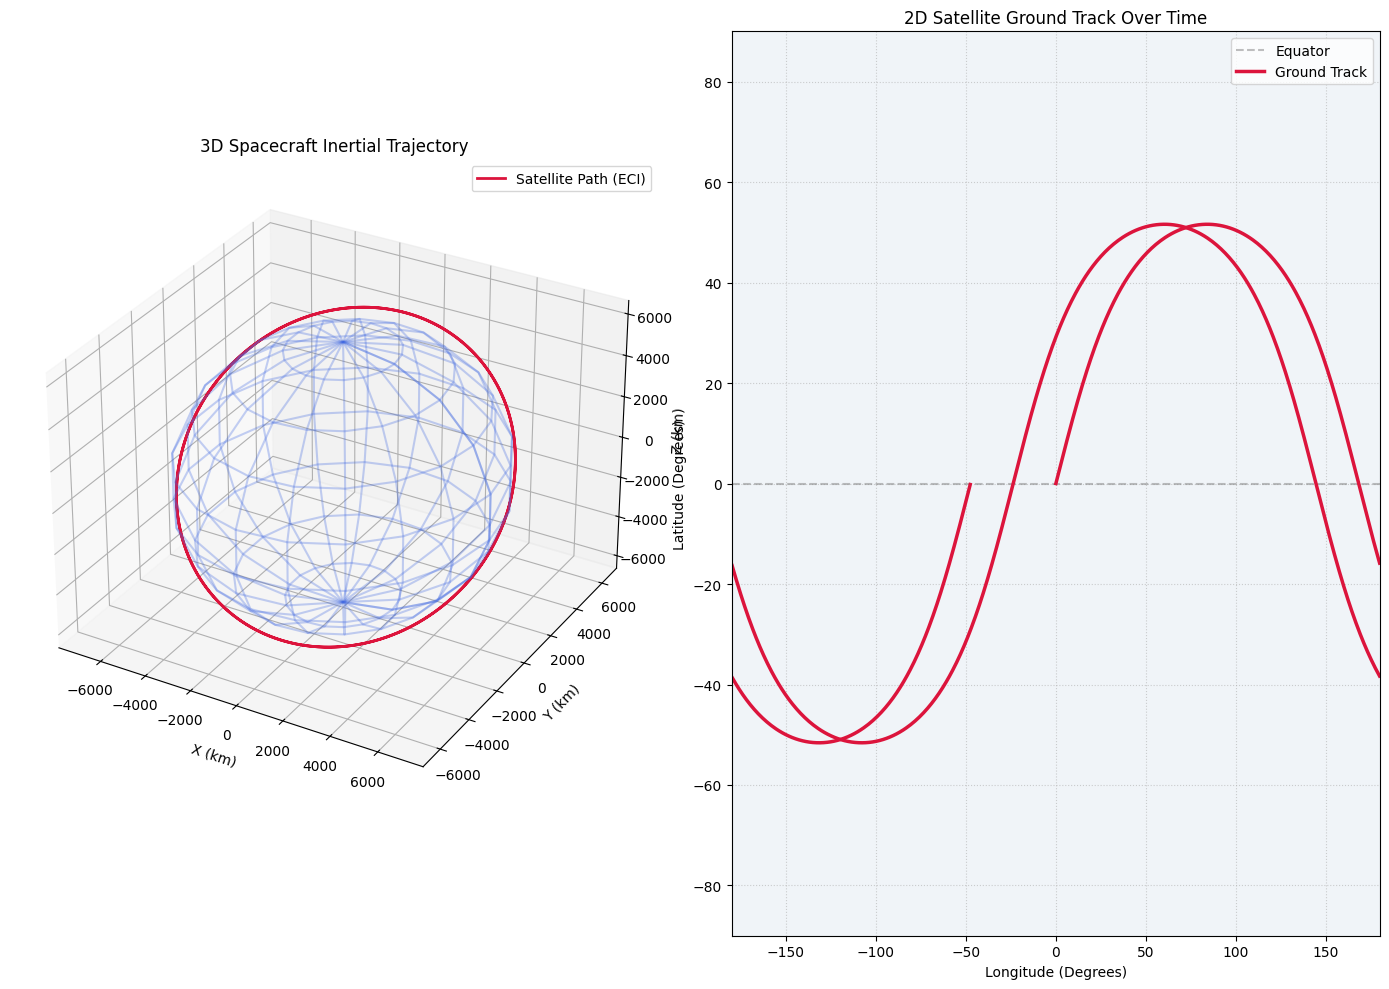

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. PARAMETERS & INITIALIZATION
# ==========================================
# Earth Constants
R_E = 6378.137          # Earth's equatorial radius (km)
mu = 398600.4418        # Earth's gravitational parameter (km^3/s^2)
omega_E = 7.292115e-5   # Earth's rotation speed (rad/s)

# Orbital Elements (Keplerian)
altitude = 500.0        # Altitude above Earth surface (km)
a = R_E + altitude      # Semi-major axis (km)
e = 0.001               # Eccentricity (near-circular)
i = np.radians(51.6)    # Inclination (rad) - e.g., ISS orbit
Omega = np.radians(0)   # RAAN (rad)
omega = np.radians(0)   # Argument of Perigee (rad)

# Time Simulation setup
period = 2 * np.pi * np.sqrt(a**3 / mu)  # Orbital period (seconds)
num_orbits = 2                           # Number of orbits to simulate
t_max = period * num_orbits
dt = 10                                  # Time step size (seconds)
time_steps = np.arange(0, t_max, dt)

# Arrays to store tracking data
lats = []
longs = []
x_eci, y_eci, z_eci = [], [], []

# ==========================================
# 2. ORBITAL PROPAGATION & COORDINATE TRANSFORMS
# ==========================================
for t in time_steps:
    # Mean anomaly calculation assuming constant angular speed (circular approximation)
    M = (2 * np.pi / period) * t
    nu = M  # True anomaly equals mean anomaly for near-circular orbits

    # Position in the orbital plane (Perifocal frame)
    r = a * (1 - e**2) / (1 + e * np.cos(nu))
    x_w = r * np.cos(nu)
    y_w = r * np.sin(nu)

    # 3D Rotation matrices from Perifocal to Earth-Centered Inertial (ECI) Frame
    # R3(Omega) * R1(i) * R3(omega)
    cos_O, sin_O = np.cos(Omega), np.sin(Omega)
    cos_i, sin_i = np.cos(i), np.sin(i)
    cos_w, sin_w = np.cos(omega), np.sin(omega)

    X_eci = x_w * (cos_O*cos_w - sin_O*sin_w*cos_i) + y_w * (-cos_O*sin_w - sin_O*cos_w*cos_i)
    Y_eci = x_w * (sin_O*cos_w + cos_O*sin_w*cos_i) + y_w * (-sin_O*sin_w + cos_O*cos_w*cos_i)
    Z_eci = x_w * (sin_w*sin_i)                     + y_w * (cos_w*sin_i)

    x_eci.append(X_eci)
    y_eci.append(Y_eci)
    z_eci.append(Z_eci)

    # Convert ECI to Earth-Centered Earth-Fixed (ECEF) by rotating with Earth's spin
    theta_gst = omega_E * t  # Greenwich Sidereal Time approximation
    X_ecef = X_eci * np.cos(theta_gst) + Y_eci * np.sin(theta_gst)
    Y_ecef = -X_eci * np.sin(theta_gst) + Y_eci * np.cos(theta_gst)
    Z_ecef = Z_eci

    # Convert ECEF to Geodetic Latitude and Longitude
    lat = np.arcsin(Z_ecef / np.sqrt(X_ecef**2 + Y_ecef**2 + Z_ecef**2))
    lon = np.arctan2(Y_ecef, X_ecef)

    lats.append(np.degrees(lat))
    longs.append(np.degrees(lon))

# Clean up longitude jumps for clean line drawing on 2D maps
longs = np.array(longs)
lats = np.array(lats)
diffs = np.diff(longs)
jumps = np.where(np.abs(diffs) > 180)[0]
longs_split = np.split(longs, jumps + 1)
lats_split = np.split(lats, jumps + 1)

# ==========================================
# 3. VISUALIZATION
# ==========================================
fig = plt.figure(figsize=(14, 10))

# Subplot 1: 3D Inertial Orbit Space
ax1 = fig.add_subplot(2, 2, (1, 3), projection='3d')
# Draw Earth sphere skeleton
u, v = np.mgrid[0:2*np.pi:20j, 0:np.pi:10j]
xs = R_E * np.cos(u) * np.sin(v)
ys = R_E * np.sin(u) * np.sin(v)
zs = R_E * np.cos(v)
ax1.plot_wireframe(xs, ys, zs, color="royalblue", alpha=0.3)
# Plot 3D trajectory loop
ax1.plot(x_eci, y_eci, z_eci, color="crimson", lw=2, label="Satellite Path (ECI)")
ax1.set_title("3D Spacecraft Inertial Trajectory")
ax1.set_xlabel("X (km)")
ax1.set_ylabel("Y (km)")
ax1.set_zlabel("Z (km)")
ax1.legend()

# Subplot 2: 2D Projected Ground Track Map
ax2 = fig.add_subplot(2, 2, (2, 4))
ax2.set_facecolor('#f0f4f8')
# Draw map boundaries
ax2.axhline(0, color='gray', linestyle='--', alpha=0.5, label="Equator")
# Draw continuous track line segments
for i, (lon_seg, lat_seg) in enumerate(zip(longs_split, lats_split)):
    if i == 0:
        ax2.plot(lon_seg, lat_seg, color='crimson', lw=2.5, label='Ground Track')
    else:
        ax2.plot(lon_seg, lat_seg, color='crimson', lw=2.5)

ax2.set_xlim([-180, 180])
ax2.set_ylim([-90, 90])
ax2.set_title("2D Satellite Ground Track Over Time")
ax2.set_xlabel("Longitude (Degrees)")
ax2.set_ylabel("Latitude (Degrees)")
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()


In [17]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.animation as animation
import matplotlib.pyplot as plt
from netCDF4 import Dataset
import numpy as np

file_path = "/content/orbit_2026_10_01.nc"

try:
    with Dataset(file_path, "r") as nc_file:
        lat = nc_file.variables["latitude_deg"][:]
        lon = nc_file.variables["longitude_deg"][:]

    # Downsample the data for smooth and fast video generation
    step = 500
    lat_sub = lat[::step]
    lon_sub = lon[::step]

    # Break tracks across the Antimeridian to prevent horizontal streaks
    lon_diff = np.abs(np.diff(lon_sub))
    break_indices = np.where(lon_diff > 180)[0]

    lon_plot = lon_sub.copy().astype(float)
    lat_plot = lat_sub.copy().astype(float)
    if len(break_indices) > 0:
        lon_plot = np.insert(lon_plot, break_indices + 1, np.nan)
        lat_plot = np.insert(lat_plot, break_indices + 1, np.nan)

    # Set up the figure and map axis
    fig = plt.figure(figsize=(12, 6))
    ax = plt.axes(projection=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linestyle=":", alpha=0.5)
    ax.add_feature(cfeature.LAND, color="#f0f0f0")
    ax.add_feature(cfeature.OCEAN, color="#e4f1fe")
    ax.set_global()

    # Empty line plot that will be updated in animation
    line, = ax.plot([], [], color="crimson", linewidth=1.8, transform=ccrs.PlateCarree(), label="Orbital Track")
    # Red dot pointing at current location
    current_point, = ax.plot([], [], color="black", marker="o", markersize=6, transform=ccrs.PlateCarree())

    plt.title("Satellite Orbital Pass Animation", fontsize=14, pad=10)
    ax.legend(loc="upper right")

    def init():
        line.set_data([], [])
        current_point.set_data([], [])
        return line, current_point

    def update(frame):
        # Accumulate the track up to the current frame index
        line.set_data(lon_plot[:frame], lat_plot[:frame])

        # Track back to find the latest valid coordinate that is not NaN
        latest_idx = frame - 1
        while latest_idx >= 0 and np.isnan(lon_plot[latest_idx]):
            latest_idx -= 1

        if latest_idx >= 0:
            current_point.set_data([lon_plot[latest_idx]], [lat_plot[latest_idx]])
        else:
            current_point.set_data([], [])

        return line, current_point

    # Build the animation
    total_frames = len(lon_plot)
    ani = animation.FuncAnimation(
        fig, update, frames=total_frames, init_func=init, interval=30, blit=True
    )

    # Save video as MP4
    video_path = "/content/orbital_pass.mp4"
    writervideo = animation.FFMpegWriter(fps=30)
    ani.save(video_path, writer=writervideo)
    plt.close()
    print(f"Video successfully saved as {video_path}")

except Exception as e:
    print(f"An error occurred while creating the video: {e}")

/usr/local/lib/python3.13/dist-packages/shapely/creation.py:225: RuntimeWarning: invalid value encountered in linestrings
  return lib.linestrings(coords, np.intc(handle_nan), out=out, **kwargs)
/usr/local/lib/python3.13/dist-packages/shapely/creation.py:225: RuntimeWarning: invalid value encountered in linestrings
  return lib.linestrings(coords, np.intc(handle_nan), out=out, **kwargs)
/usr/local/lib/python3.13/dist-packages/shapely/creation.py:225: RuntimeWarning: invalid value encountered in linestrings
  return lib.linestrings(coords, np.intc(handle_nan), out=out, **kwargs)
/usr/local/lib/python3.13/dist-packages/shapely/creation.py:225: RuntimeWarning: invalid value encountered in linestrings
  return lib.linestrings(coords, np.intc(handle_nan), out=out, **kwargs)
/usr/local/lib/python3.13/dist-packages/shapely/creation.py:225: RuntimeWarning: invalid value encountered in linestrings
  return lib.linestrings(coords, np.intc(handle_nan), out=out, **kwargs)
/usr/local/lib/python3.13

Video successfully saved as /content/orbital_pass.mp4


In [18]:
from IPython.display import HTML
from base64 import b64encode
import os

# Display the video in the notebook
if os.path.exists("/content/orbital_pass.mp4"):
    mp4 = open("/content/orbital_pass.mp4", "rb").read()
    data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
    display(HTML(f"""
    <video width=850 controls autoplay loop>
          <source src="{data_url}" type="video/mp4">
    </video>
    """))
else:
    print("Video file not found.")

In [20]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
from netCDF4 import Dataset
import numpy as np

# Replace with your actual file path
file_path = "/content/orbit_2026_10_01.nc"

try:
  with Dataset(file_path, "r") as nc_file:
    # Extract latitude and longitude variables
    lat = nc_file.variables["latitude"][:]
    lon = nc_file.variables["longitude"][:]

    # Handle International Date Line wrapping to prevent streak artifacts
    lon_diff = np.abs(np.diff(lon))
    break_indices = np.where(lon_diff > 180)[0]

    lon_plot = lon.copy().astype(float)
    lat_plot = lat.copy().astype(float)
    if len(break_indices) > 0:
      lon_plot = np.insert(lon_plot, break_indices + 1, np.nan)
      lat_plot = np.insert(lat_plot, break_indices + 1, np.nan)

    # Create the figure using an elliptical global projection (Mollweide)
    fig = plt.figure(figsize=(12, 7))
    ax = plt.axes(
        projection=ccrs.Mollweide()
    )  # Gives the rounded global shape

    # Add background map features
    ax.add_feature(cfeature.LAND, color="#222222")  # Dark land style
    ax.add_feature(cfeature.OCEAN, color="#111111")  # Dark ocean style
    ax.add_feature(cfeature.COASTLINE, edgecolor="gray", linewidth=0.5)

    # Plot the orbital path / swaths
    # transform=ccrs.PlateCarree() tells Cartopy that your input data is in standard lat/lon
    ax.plot(
        lon_plot,
        lat_plot,
        color="cyan",
        linewidth=1.2,
        transform=ccrs.PlateCarree(),
        label="Orbital Tracks",
    )

    # Optional: Add subtle gridlines for the global view
    ax.gridlines(color="gray", alpha=0.3, linestyle="--")

    plt.title(
        "Satellite Constellation Global Coverage",
        color="white",
        fontsize=14,
        pad=15,
    )

    # Set background color of the plot area to match a dark theme
    fig.patch.set_facecolor("#0b0b0b")
    ax.set_facecolor("#0b0b0b")

    plt.show()

except Exception as e:
  print(f"Error processing orbital data: {e}")

Error processing orbital data: 'latitude'
